<a href="https://colab.research.google.com/github/ganesh7207/AI-ML-Projects/blob/main/ImageCaptioning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
## Step 1 — Install and load BLIP


# Image Captioning with BLIP
### AI that describes what it sees in an image!



In [ ]:
!pip install transformers gradio pillow -q

from transformers import BlipProcessor, BlipForConditionalGeneration
from transformers.utils import logging
import warnings
warnings.filterwarnings('ignore')
logging.set_verbosity_error()

print('Loading BLIP model...')
processor  = BlipProcessor.from_pretrained(
                 'Salesforce/blip-image-captioning-base')
blip_model = BlipForConditionalGeneration.from_pretrained(
                 'Salesforce/blip-image-captioning-base')
print('BLIP ready!')


Loading BLIP model...


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

BLIP ready!


---
## Step 2 — Get a sample image

> We try to download a reliable sample image.
> If that fails — a test image is created automatically.
> In the Gradio app you can upload YOUR OWN photo!


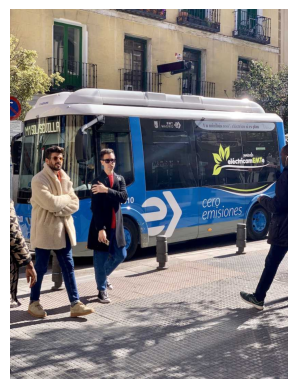

Image size: (810, 1080)


In [ ]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

# Download an image
url = "https://ultralytics.com/images/bus.jpg"
response = requests.get(url)

# Load the image
image = Image.open(BytesIO(response.content)).convert("RGB")

# Display the image
plt.imshow(image)
plt.axis("off")
plt.show()

# Print image size
print("Image size:", image.size)

https://ultralytics.com/images/zidane.jpg'

---
## Step 3 — Create the caption function

> This function takes an image and returns a sentence.
> Same idea as the translate() and summarize() functions we built before!


In [ ]:
def get_caption(image):
    # Step A: prepare the image for BLIP
    inputs = processor(image.convert('RGB'), return_tensors='pt')

    # Step B: generate the caption
    with torch.no_grad():
        output = blip_model.generate(**inputs, max_new_tokens=50)

    # Step C: convert numbers back to text
    caption = processor.decode(output[0], skip_special_tokens=True)
    return caption

print('get_caption() function ready!')


get_caption() function ready!


---
## Step 4 — Generate your first caption!

> Look at the image above.
> Write what YOU think is in it.
> Then run this cell — see if BLIP agrees!


In [ ]:
import torch

caption = get_caption(image)

print("BLIP says:")
print(f'  "{caption}"')
print()
print(f"Word count: {len(caption.split())} words")

BLIP says:
  "a group of people walking around a bus"

Word count: 8 words


PyTorch (torch) is a Python library used to build, train, and run Artificial Intelligence (AI) and Machine Learning (ML) models.
In your BLIP image captioning project, torch helps the model process an image and generate a description of it.

In [ ]:
def get_caption_with_prompt(image, prompt):
    # Same as before — but we add a starting text
    inputs = processor(image.convert('RGB'),
                       text   = prompt,
                       return_tensors = 'pt')
    with torch.no_grad():
        output = blip_model.generate(**inputs, max_new_tokens=50)
    return processor.decode(output[0], skip_special_tokens=True)


# Same image — different starting prompts
prompts = [
    'a photo of',
    'this image shows',
    'there are',
]

print('Same image — different prompts:')
print()
for prompt in prompts:
    result = get_caption_with_prompt(image, prompt)
    print(f'Prompt  : "{prompt}"')
    print(f'Caption : "{result}"')
    print()


Same image — different prompts:

Prompt  : "a photo of"
Caption : "a photo of a bus in the street"

Prompt  : "this image shows"
Caption : "this image shows a bus with a blue and white livery"

Prompt  : "there are"
Caption : "there are people walking around a bus"



---
## Step 5 — Guide the caption with a prompt


In [ ]:
import pandas as pd

token_lengths = [20, 40, 60, 80]
results = []

for max_t in token_lengths:
    inputs = processor(image.convert('RGB'), return_tensors='pt')
    with torch.no_grad():
        output = blip_model.generate(**inputs, max_new_tokens=max_t)
    cap   = processor.decode(output[0], skip_special_tokens=True)
    words = len(cap.split())
    results.append({'max_tokens': max_t, 'words': words, 'caption': cap})
    print(f'max_tokens={max_t:3d} → {words} words: {cap}')

print()
print('More tokens = longer caption')
print('But after a point the caption does not grow much more')


max_tokens= 20 → 8 words: a group of people walking around a bus
max_tokens= 40 → 8 words: a group of people walking around a bus
max_tokens= 60 → 8 words: a group of people walking around a bus
max_tokens= 80 → 8 words: a group of people walking around a bus

More tokens = longer caption
But after a point the caption does not grow much more


---
## Step 7 — How does max_new_tokens affect the caption?




## MULTIPLE IMAGES

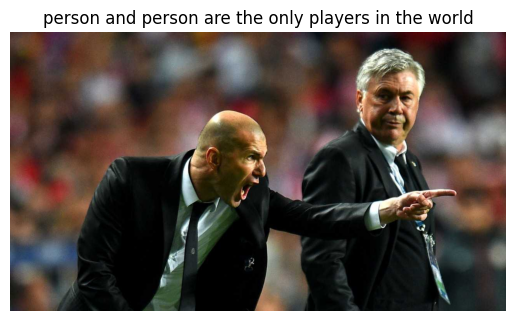

Caption: person and person are the only players in the world


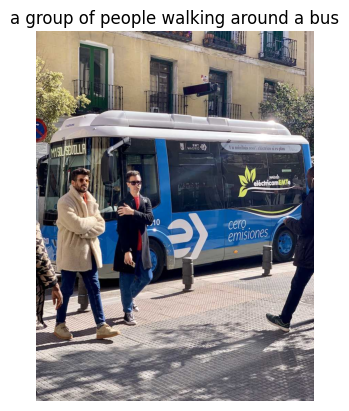

Caption: a group of people walking around a bus


In [ ]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

urls = [
    "https://ultralytics.com/images/zidane.jpg",
    "https://ultralytics.com/images/bus.jpg"
]

for url in urls:
    try:
        # Download and open image
        img = Image.open(BytesIO(requests.get(url).content)).convert("RGB")

        # Generate caption using BLIP
        caption = get_caption(img)

        # Display image and caption
        plt.imshow(img)
        plt.axis("off")
        plt.title(caption, wrap=True)
        plt.show()

        print("Caption:", caption)

    except Exception as e:
        print("Error:", e)

In [ ]:
import gradio as gr

def caption_app(uploaded_image, prompt):
    if uploaded_image is None:
        return 'Please upload an image first!'

    img = uploaded_image.convert('RGB')

    # Use prompt if given, otherwise plain caption
    if prompt.strip():
        caption = get_caption_with_prompt(img, prompt)
    else:
        caption = get_caption(img)

    word_count = len(caption.split())
    return f'Caption:\n"{caption}"\n\nWords: {word_count}'


app = gr.Interface(
    fn      = caption_app,
    inputs  = [
        gr.Image(
            type  = 'pil',
            label = 'Upload any image'
        ),
        gr.Textbox(
            label       = 'Starting prompt (optional)',
            placeholder = 'Example: a photo of    OR leave empty',
            lines       = 1
        )
    ],
    outputs     = gr.Textbox(label='AI Caption', lines=4),
    title       = 'Image Captioning — BLIP',
    description = 'Upload any image — AI writes a sentence about it!'
)

app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://32b0f7279692b78fd2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
## Step 8 — Build a Gradio Caption App




In [ ]:
app.close()
print('App closed.')
